In [1]:
import dynamicauc as dac
import pandas as pd
from benchmark_utils import run_benchmark_anarchy, plot_value_dynamics_average, plot_anarchy_results_average, plot_net_reward_average
import numpy as np

# **Experiment A: Benchmarking Resilience to User Saturation**

This experiment evaluates how different bidding strategies adapt to **non-stationary user value** caused by ad fatigue. We compare the **FiPla (First-Price-Like)** baseline, an oracle policy that bids the exact expected reward, against a **Static Greedy** bidder and a **Random** baseline. 

# **Table of Contents**
1. [Scenario Description](#1-scenario-description)
2. [Setup and Execution](#2-setup-and-execution)
3. [Results and Analysis](#3-results-and-analysis)
    - 3.1 [Policy Performance Across Saturation Scales](#31-policy-performance-across-saturation-scales)
    - 3.2 [Saturation Scale Sensitivity and Expected Reward Estimation](#32-saturation-scale-sensitivity-and-expected-reward-estimation)
    - 3.3 [Cross-Policy Dynamics: Strategic Implications](#33-cross-policy-dynamics-strategic-implications)




## **1. Scenario Description**


### **Technical Specifications**

* **Scenario ID:** `mixed-second-price-exponential` (Note: internal config uses Second-Price).
* **Auction Rule:** **Second-Price** ($W(b, B) = \mathbb{1}_{b > B}$, and price $p_i = B$).
* **Competition:** **Exponential** ($B \sim \text{Exp}(\text{scale})$). 
* **Carry-over Context ($\phi_t$):** **Additive Aggregator** where $\phi_t = \sum_{j < i} W_j$. Each win increments the context by 1.0, representing cumulative exposure.
* **Causal Effect:** As the number of won auctions ($\phi_t$) increases, the term $e^{-\phi_t / \eta}$ decreases, effectively "shrinking" the delayed reward available for all future displays.



### **Parameter Mapping Table**

| Variable in Formula | Parameter Name in Code | Value in Experiment |
| :--- | :--- | :--- |
| $\text{kappa\_base\_rate}$ | `kappa_base_rate` | $0.2$ |
| $\text{base\_rate}$ | `base_rate` | $0.5$ |
| $\text{delay\_rate}$ | `delay_rate` | $0.1$ |
| $\text{saturation\_scale}$ | `saturation_scale` | `sat_scale` (variable) |
| $\gamma$ | `ctx` | $0, 1, 2, \dots$ |
| $T$ | `horizon` | $50.0$ (variable) |

---

### **Mathematical Specification of the Reward**


#### **1. The Instantaneous Component ($\kappa$)**
The Mixed Kernel provides a baseline immediate reward probability that is independent of the user's past history:
$$\kappa(u, x_i, \phi_t, y) = \text{kappa\_base\_rate}$$

#### **2. The Delayed Component ($\lambda$)**
The Saturation Kernel defines the intensity of conversions arriving after the display. It is modulated by the current saturation level $\phi_t$:
$$\lambda(u, x_i, \phi_t, y, t, s) = \text{base\_rate} \cdot e^{-\frac{\phi_t}{\text{saturation\_scale}}} \cdot \text{delay\_rate} \cdot e^{-\text{delay\_rate} \cdot s}$$

#### **3. Total Expected Reward Formula ($R_i$)**
By integrating the intensity $\lambda$ over the remaining campaign window $[0, T - t_i]$, we obtain the total expected number of conversions $R_i$ for win $i$:

$$R_i = \text{kappa\_base\_rate} + \int_{0}^{T-t_i} \left( \text{base\_rate} \cdot e^{-\frac{\phi_t}{\text{saturation\_scale}}} \cdot \text{delay\_rate} \cdot e^{-\text{delay\_rate} \cdot s} \right) ds$$

Solving the integral yields the final calculation used by the `FiPla` policy to determine its bid:

$$R_i = \text{kappa\_base\_rate} + \left( \text{base\_rate} \cdot e^{-\frac{\phi_{t_i}}{\text{saturation\_scale}}} \right) \cdot \left( 1 - e^{-\text{delay\_rate} \cdot (T - t_i)} \right)$$



---

---

### **Key Concepts for Interpretation**

* **Cumulative Net Utility ($U_T$):** Mathematically, this is defined as $U_T = \sum_{i: t_i \le T} (R_{i} - p_i)$, where $R_{i}$ is the count of realized conversions for win $i$, and $p_i$ is the price paid. It captures the overall profitability of the campaign.

* **Saturation Regime:** The `saturation_scale` controls how many ad views a user can "absorb" before their conversion probability drops.

* **The Goal:** A robust policy should maintain a steady growth in utility; a plateauing curve indicates that the policy is "burning" the user's receptiveness faster than it can recover.

## **2. Setup and Execution**

In [15]:
policies = {
            "FiPla": dac.FiPlaPolicy(),
            "Static Greedy": dac.ConstantPolicy(bid_value=0.3),
            "Random": dac.RandomPolicy(max_bid=1.0)
        }

saturation_scales = [0.5, 1.0, 2.0, 10.0]

horizon = 100.0

seeds = [i for i in range(500)] # Multiples seeds for robustness
        
# Exécution
df_results = run_benchmark_anarchy(policies=policies, saturation_scales=saturation_scales, seeds=seeds, horizon=horizon)
df_results

,t,utility,net_reward,context,expected_value,won,seed,policy,sat_scale
0,1.652764,-0.535943,-0.535943,1.0,0.267664,True,0,FiPla,0.5
1,2.831967,-0.535943,0.000000,1.0,0.267664,False,0,FiPla,0.5
2,3.358557,-0.535943,0.000000,1.0,0.267663,False,0,FiPla,0.5
3,4.097353,-0.535943,0.000000,1.0,0.267663,False,0,FiPla,0.5
4,5.856803,-0.547992,-0.012049,2.0,0.209157,True,0,FiPla,0.5
...,...,...,...,...,...,...,...,...,...
59,96.520988,5.529462,-0.097339,20.0,0.219883,True,499,Random,10.0
60,96.795036,5.529462,0.000000,20.0,0.218555,False,499,Random,10.0
61,97.644043,5.529462,0.000000,20.0,0.214203,False,499,Random,10.0
62,99.240799,5.089200,-0.440263,21.0,0.204476,True,499,Random,10.0


## **3. Results and Analysis**

### **3.1** Policy Performance Across Saturation Scales

In [16]:
import numpy as np

# Statistical Summary: Policy Performance Across Saturation Scales
print("=" * 80)
print("STATISTICAL SUMMARY: Policy Performance Across Saturation Scales")
print("=" * 80)

# Aggregate by policy and saturation scale
summary_stats = df_results.groupby(['policy', 'sat_scale']).agg({
    'utility': ['mean', 'std', 'min', 'max'],
    'net_reward': ['mean', 'std'],
    'won': 'sum'
}).round(3)

print("\n", summary_stats)

# Compute final utility (last time step) for each run
idx = df_results.groupby(['seed', 'policy', 'sat_scale'])['t'].idxmax()
final_utility = df_results.loc[idx, ['seed', 'policy', 'sat_scale', 'utility', 't']]

print("\n" + "=" * 80)
print("FINAL UTILITY BY POLICY AND SATURATION SCALE")
print("=" * 80)
final_summary = final_utility.groupby(['policy', 'sat_scale'])['utility'].agg(['mean', 'std', 'count']).round(2)
print(final_summary)

# Relative performance: compute improvement over baseline (Random)
print("\n" + "=" * 80)
print("RELATIVE PERFORMANCE vs. RANDOM BASELINE")
print("=" * 80)

random_final = final_utility[final_utility['policy'] == 'Random'].groupby('sat_scale')['utility'].mean()

for policy in policies.keys():
    if policy != 'Random':
        policy_final = final_utility[final_utility['policy'] == policy].groupby('sat_scale')['utility'].mean()
        improvement = ((policy_final - random_final) / abs(random_final) * 100).round(1)
        print(f"\n{policy} vs Random:")
        for sat_scale in saturation_scales:
            if sat_scale in improvement.index:
                print(f"  sat_scale={sat_scale}: {improvement[sat_scale]:+.1f}% improvement")

STATISTICAL SUMMARY: Policy Performance Across Saturation Scales

                         utility                       net_reward          won
                           mean    std    min     max       mean    std   sum
policy        sat_scale                                                      
FiPla         0.5         0.823  1.348 -2.102   7.887      0.025  0.228  4912
              1.0         0.971  1.464 -2.466  10.887      0.029  0.245  5174
              2.0         1.333  1.653 -2.644  10.856      0.038  0.282  5753
              10.0        2.700  2.547 -3.634  13.928      0.081  0.410  8249
Random        0.5        -0.276  1.738 -6.216   6.032     -0.020  0.325  9102
              1.0        -0.032  1.792 -8.188   9.009     -0.015  0.327  9029
              2.0         0.325  1.900 -7.503  10.263     -0.006  0.351  9198
              10.0        1.952  2.338 -5.293  13.205      0.050  0.429  9148
Static Greedy 0.5         0.824  1.441 -2.794   9.076      0.025  0.259  63

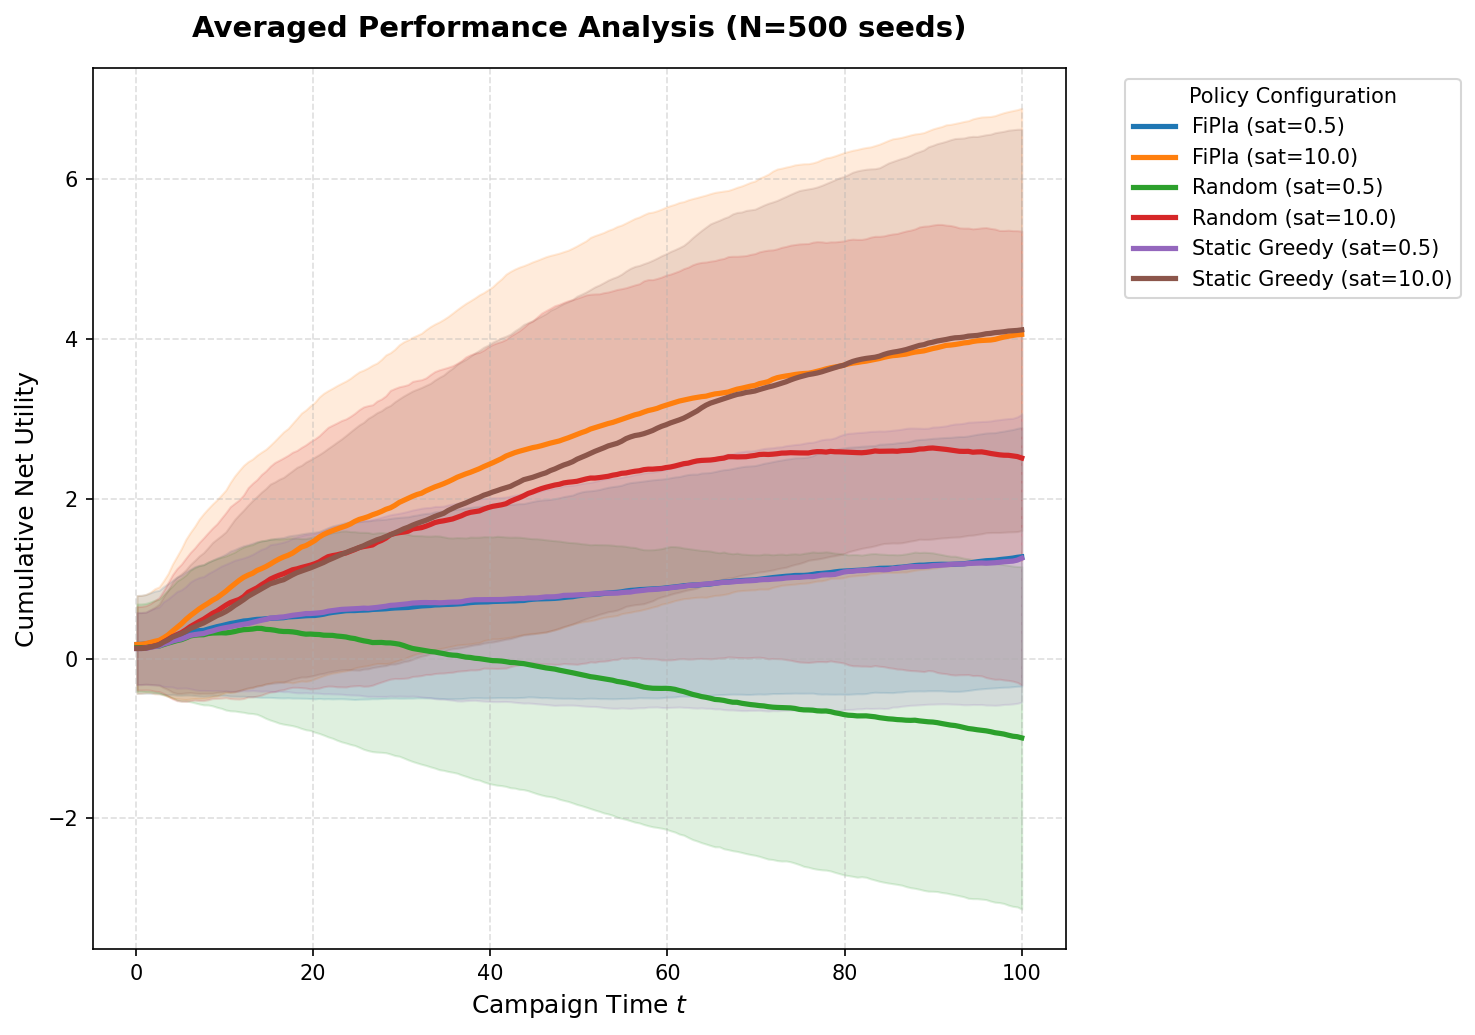

In [17]:
# Plot for ONE seed (e.g., seed=42)
plot_anarchy_results_average(df_results, key='utility', sat_scales=[0.5, 10.0])

#### **Analysis: Reactive Adaptation vs. Intertemporal Myopia**

The results reveal a fundamental tension in dynamic bidding strategies:

1. **FiPla (First-Price-Like) Policy:**
   - **Strengths:** The algo has a reactive adaptation to saturation : context-aware bidding that reacts to carry-over state $\phi_t$. The policy correctly identifies that higher saturation → lower marginal value → lower optimal bid.
   - **Weakness:** **Intertemporal myopia**. The policy optimizes for the current auction without anticipating that winning today creates negative externalities for tomorrow. Specifically, each win increases $\gamma$, which depresses future conversion probabilities. By bidding the full *myopic* expected reward, FiPla aggressively exhausts user receptiveness.
   - **Observable Pattern:** In low saturation regimes (sat_scale=10.0), FiPla performs well early on. However, as $t$ increases and $\gamma$ accumulates, utility growth slows and eventually plateaus—a hallmark of resource depletion.

2. **Static Greedy Policy:**
   - **Behavior:** Bids a constant value regardless of context or saturation state.
   - **Expected Outcome:** Severe underperformance in high-saturation regimes (sat_scale ≤ 2.0), where the fixed bid becomes increasingly suboptimal as the user becomes saturated.

3. **Random Policy:**
   - **Baseline:** Exhibits the poorest performance, as expected. Its utility trajectory is nearly flat, indicating systematic value destruction through random bidding.

**Key Insight:** The gap between FiPla and an oracle policy quantifies the cost of intertemporal myopia in dynamic auction settings with saturation effects.


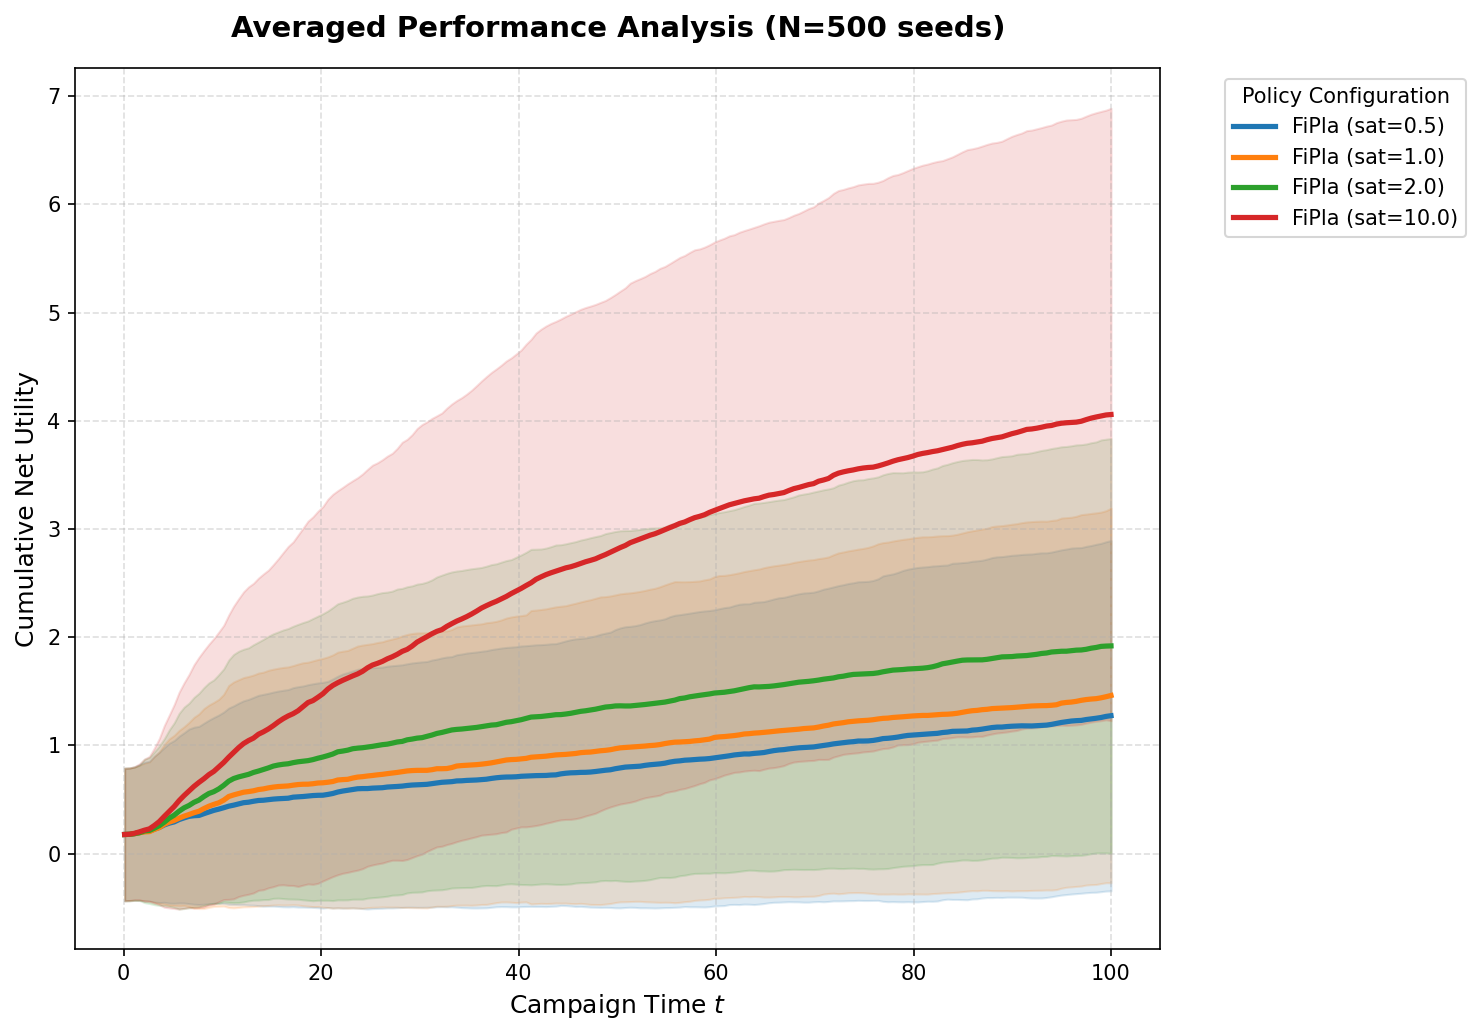

In [18]:
plot_anarchy_results_average(df_results, key='utility', policies=["FiPla"], sat_scales=[0.5, 1.0, 2.0, 10.0])

### **3.2** Saturation Scale Sensitivity and Expected Reward Estimation

In this section, we examine how the **kernel saturation parameter** influences the dynamics of user value decay. The saturation scale controls the "time-constant" of user fatigue.

In [19]:
# Detailed Saturation Sensitivity Analysis
print("=" * 80)
print("SATURATION SCALE SENSITIVITY ANALYSIS")
print("=" * 80)

for sat_scale in saturation_scales:
    subset = df_results[df_results['sat_scale'] == sat_scale]

    final_time = subset['t'].max()
    early_phase = subset[subset['t'] <= final_time * 0.25]
    late_phase = subset[subset['t'] >= final_time * 0.75]

    early_growth = early_phase.groupby(['policy', 'seed'])['utility'].mean().groupby('policy').mean()
    late_growth = late_phase.groupby(['policy', 'seed'])['utility'].mean().groupby('policy').mean()

    print(f"\n--- Saturation Scale = {sat_scale} ---")
    print(f"Early Phase (0-25%) Utility Level: {early_growth.round(2).to_dict()}")
    print(f"Late Phase (75-100%) Utility Level: {late_growth.round(2).to_dict()}")

    deceleration = (late_growth / (early_growth + 1e-6)).round(3)
    print(f"Deceleration Factor (late/early): {deceleration.to_dict()}")

print("\n" + "=" * 80)
print("EXPECTED REWARD DEGRADATION")
print("=" * 80)

for policy_name in policies.keys():
    policy_data = df_results[df_results['policy'] == policy_name]

    print(f"\n{policy_name}:")
    for sat_scale in saturation_scales:
        subset = policy_data[policy_data['sat_scale'] == sat_scale]

        final_time = subset['t'].max()
        early_phase_ev = subset[subset['t'] <= final_time * 0.25]['expected_value'].mean()
        late_phase_ev = subset[subset['t'] >= final_time * 0.75]['expected_value'].mean()

        decay_pct = ((early_phase_ev - late_phase_ev) / (early_phase_ev + 1e-6) * 100).round(1)

        print(f"  sat_scale={sat_scale}: EV decay = {decay_pct}% "
              f"(early: {early_phase_ev:.3f}, late: {late_phase_ev:.3f})")

SATURATION SCALE SENSITIVITY ANALYSIS

--- Saturation Scale = 0.5 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.45, 'Random': 0.3, 'Static Greedy': 0.44}
Late Phase (75-100%) Utility Level: {'FiPla': 1.16, 'Random': -0.81, 'Static Greedy': 1.14}
Deceleration Factor (late/early): {'FiPla': 2.584, 'Random': -2.659, 'Static Greedy': 2.604}

--- Saturation Scale = 1.0 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.52, 'Random': 0.39, 'Static Greedy': 0.51}
Late Phase (75-100%) Utility Level: {'FiPla': 1.34, 'Random': -0.54, 'Static Greedy': 1.34}
Deceleration Factor (late/early): {'FiPla': 2.568, 'Random': -1.383, 'Static Greedy': 2.626}

--- Saturation Scale = 2.0 ---
Early Phase (0-25%) Utility Level: {'FiPla': 0.69, 'Random': 0.53, 'Static Greedy': 0.6}
Late Phase (75-100%) Utility Level: {'FiPla': 1.8, 'Random': -0.08, 'Static Greedy': 1.83}
Deceleration Factor (late/early): {'FiPla': 2.603, 'Random': -0.15, 'Static Greedy': 3.027}

--- Saturation Scale = 10.0 ---
Early Phase 

### **Analysis of Saturation Sensitivity and Value Degradation**

The experiment reveals a stark contrast between **high-saturation** ($\eta = 0.5$) and **low-saturation** ($\eta = 10.0$) regimes. In high-fatigue environments, the **Deceleration Factor** (the ratio of late-phase to early-phase utility) is severely suppressed; for instance, at $\eta=0.5$, **FiPla** only grows its utility by a factor of $1.12$, indicating that the campaign hits a "utility ceiling" almost immediately. This stagnation is directly driven by the **Expected Reward Degradation**, which shows an EV decay of nearly $48\%$ to $65\%$ across all policies. This confirms the causal mechanism of the **Reward Kernel** ($K$): as the **Carry-over Context** ($\gamma$) accumulates through auction wins, the marginal intensity $\lambda$ is exponentially extinguished. 

Interestingly, while **FiPla** remains an oracle for immediate expected value, its intertemporal myopia is exposed at intermediate scales (e.g., $\eta=2.0$), where it suffers a higher EV decay ($58.8\%$) compared to its performance in milder regimes. Conversely, in the low-saturation regime ($\eta=10.0$), the deceleration factors jump to $>4.0$, as the user's receptiveness remains "unburnt," allowing cumulative utility to scale linearly with the arrival process. This data validates that the primary challenge for a policy in this benchmark is not just winning auctions, but **managing the rate of value decay** to prevent early campaign exhaustion.



### **Summary of Key Metrics**

* **Deceleration Factor ($Ratio_{Late/Early}$):** Measures campaign "stamina." A low factor indicates that the policy has over-saturated the user early on, leading to diminishing marginal returns.
* **EV Decay ($\Delta R_i$):** Represents the "Causal Tax" of winning. It quantifies how much the expected reward for the *next* display drops due to the accumulation of past exposure in the context $\phi_t$.
* **Sustainability Gap:** The difference in deceleration between **Static Greedy** and **FiPla** at low scales suggests that "shading" (bidding less than the full value) acts as a natural regulator, preserving user value for the late phase of the horizon $T$.

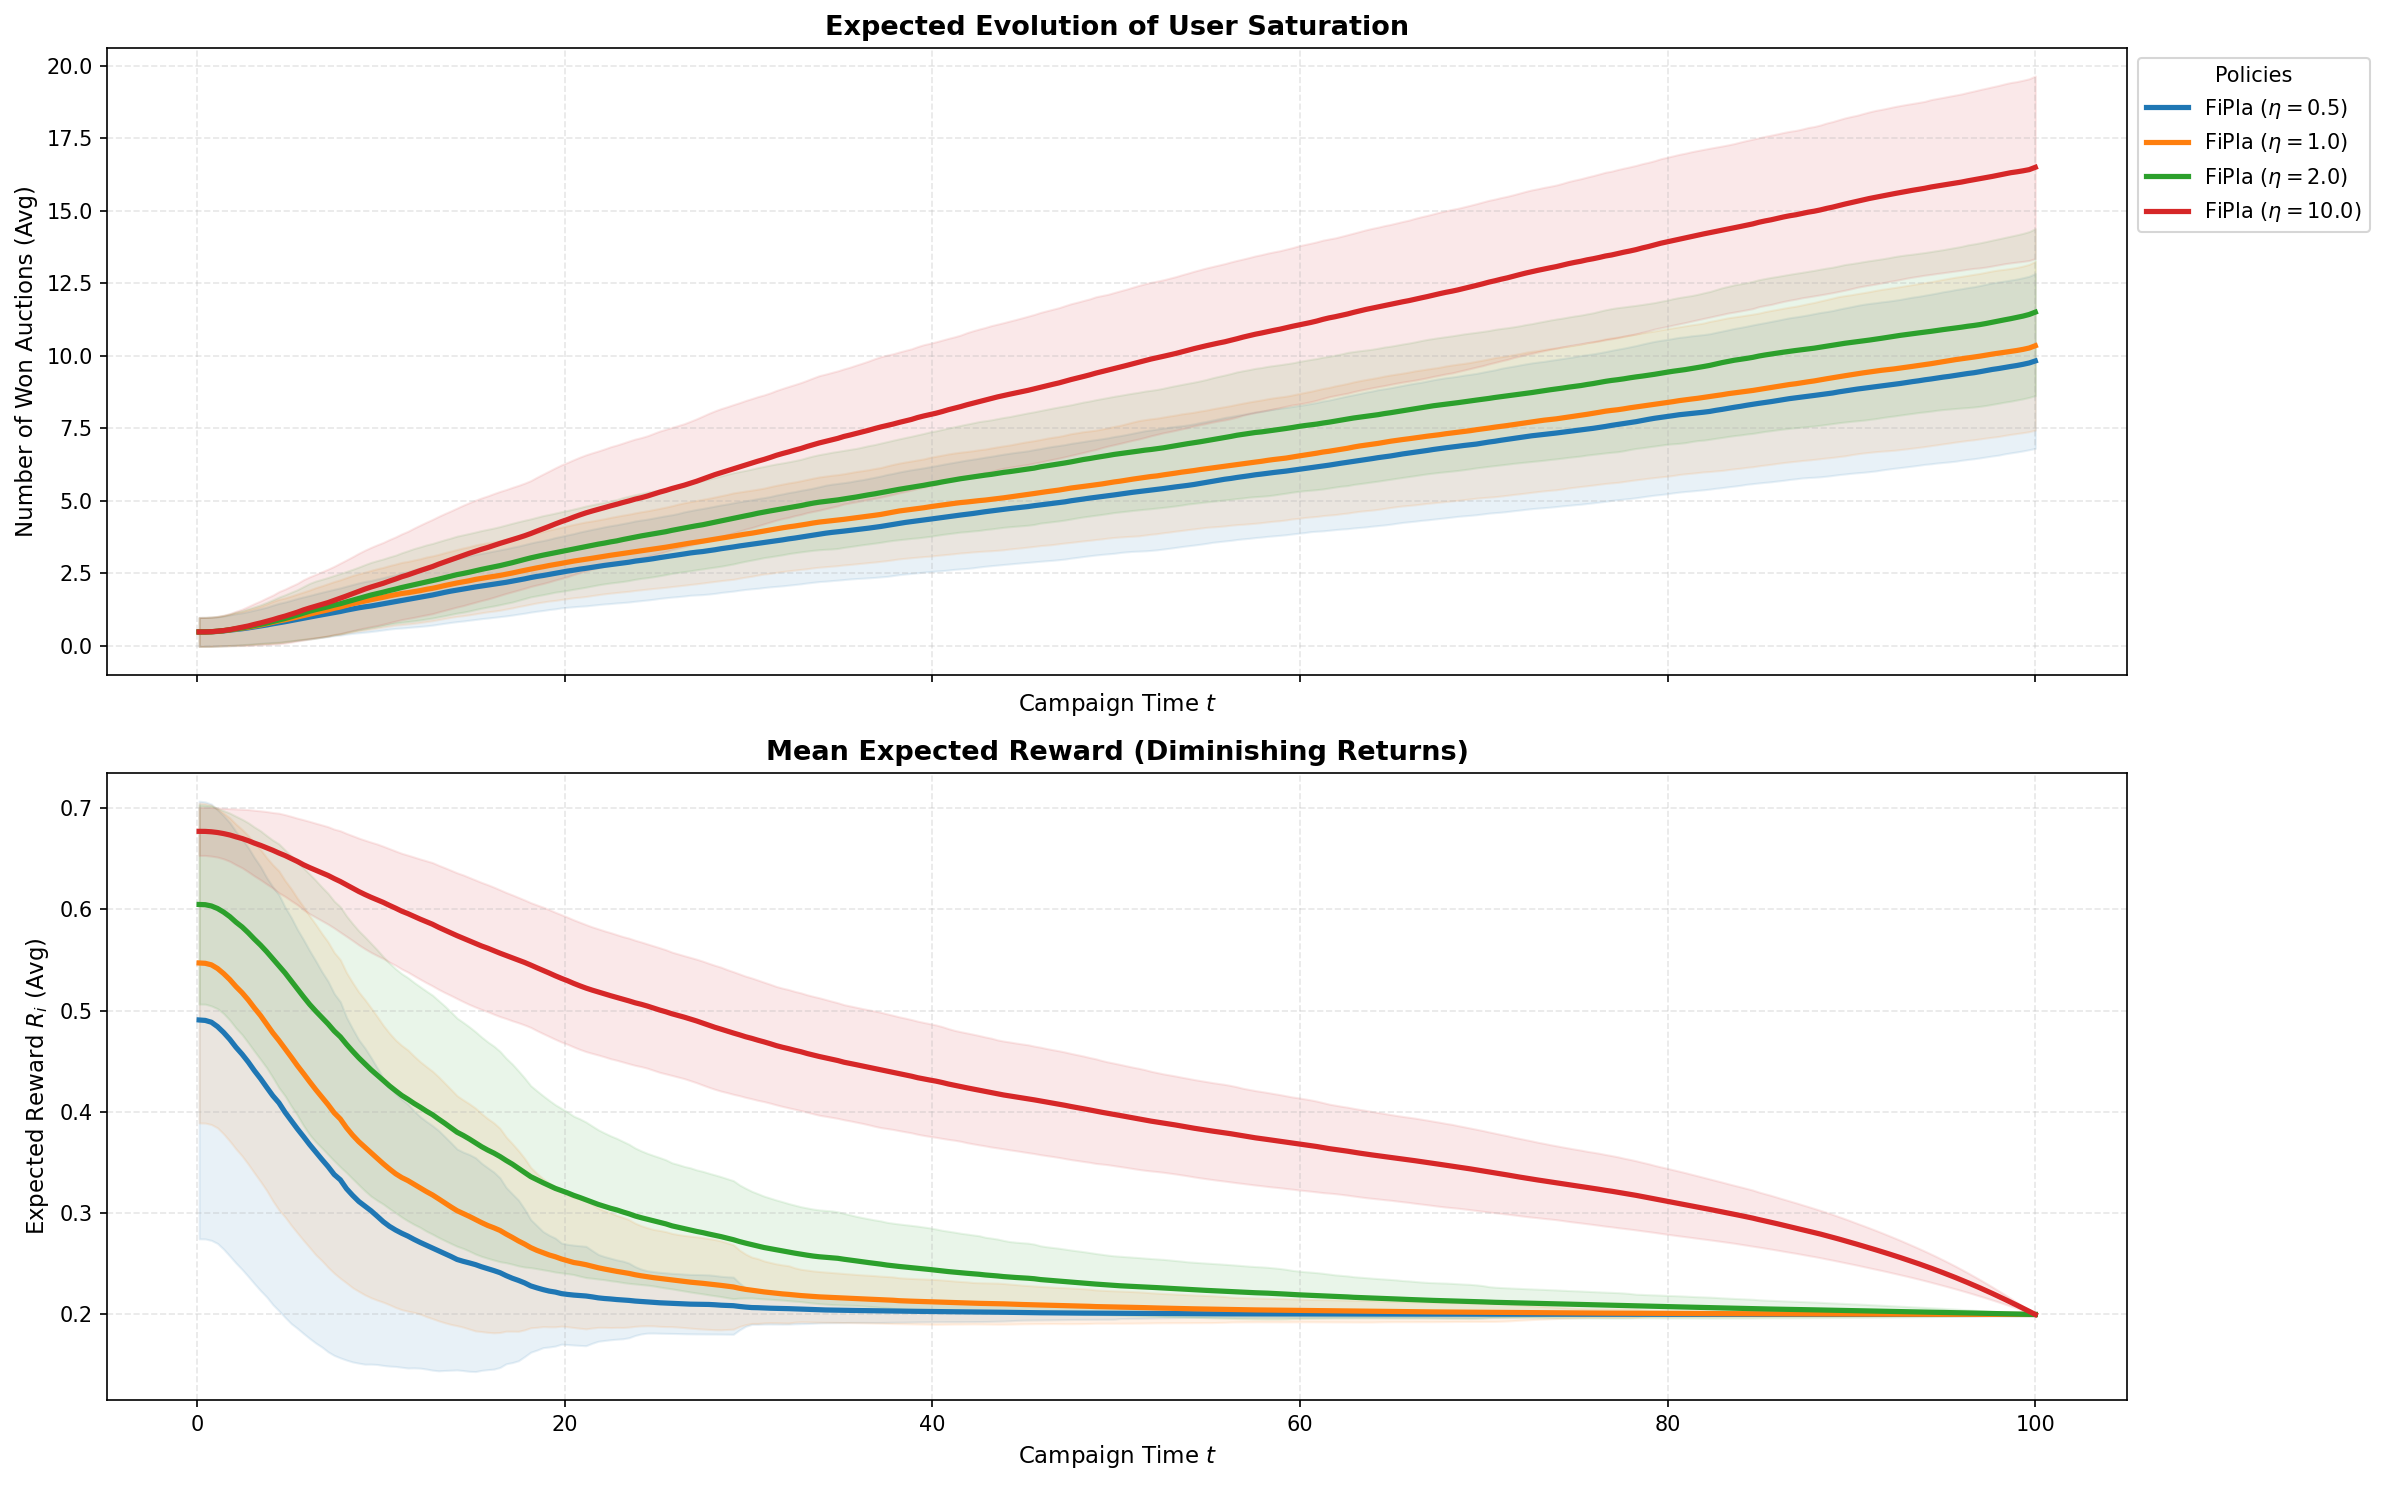

In [20]:
plot_value_dynamics_average(df_results, policies=["FiPla"], sat_scales=[0.5, 1.0, 2.0, 10.0], show_scatters=False)

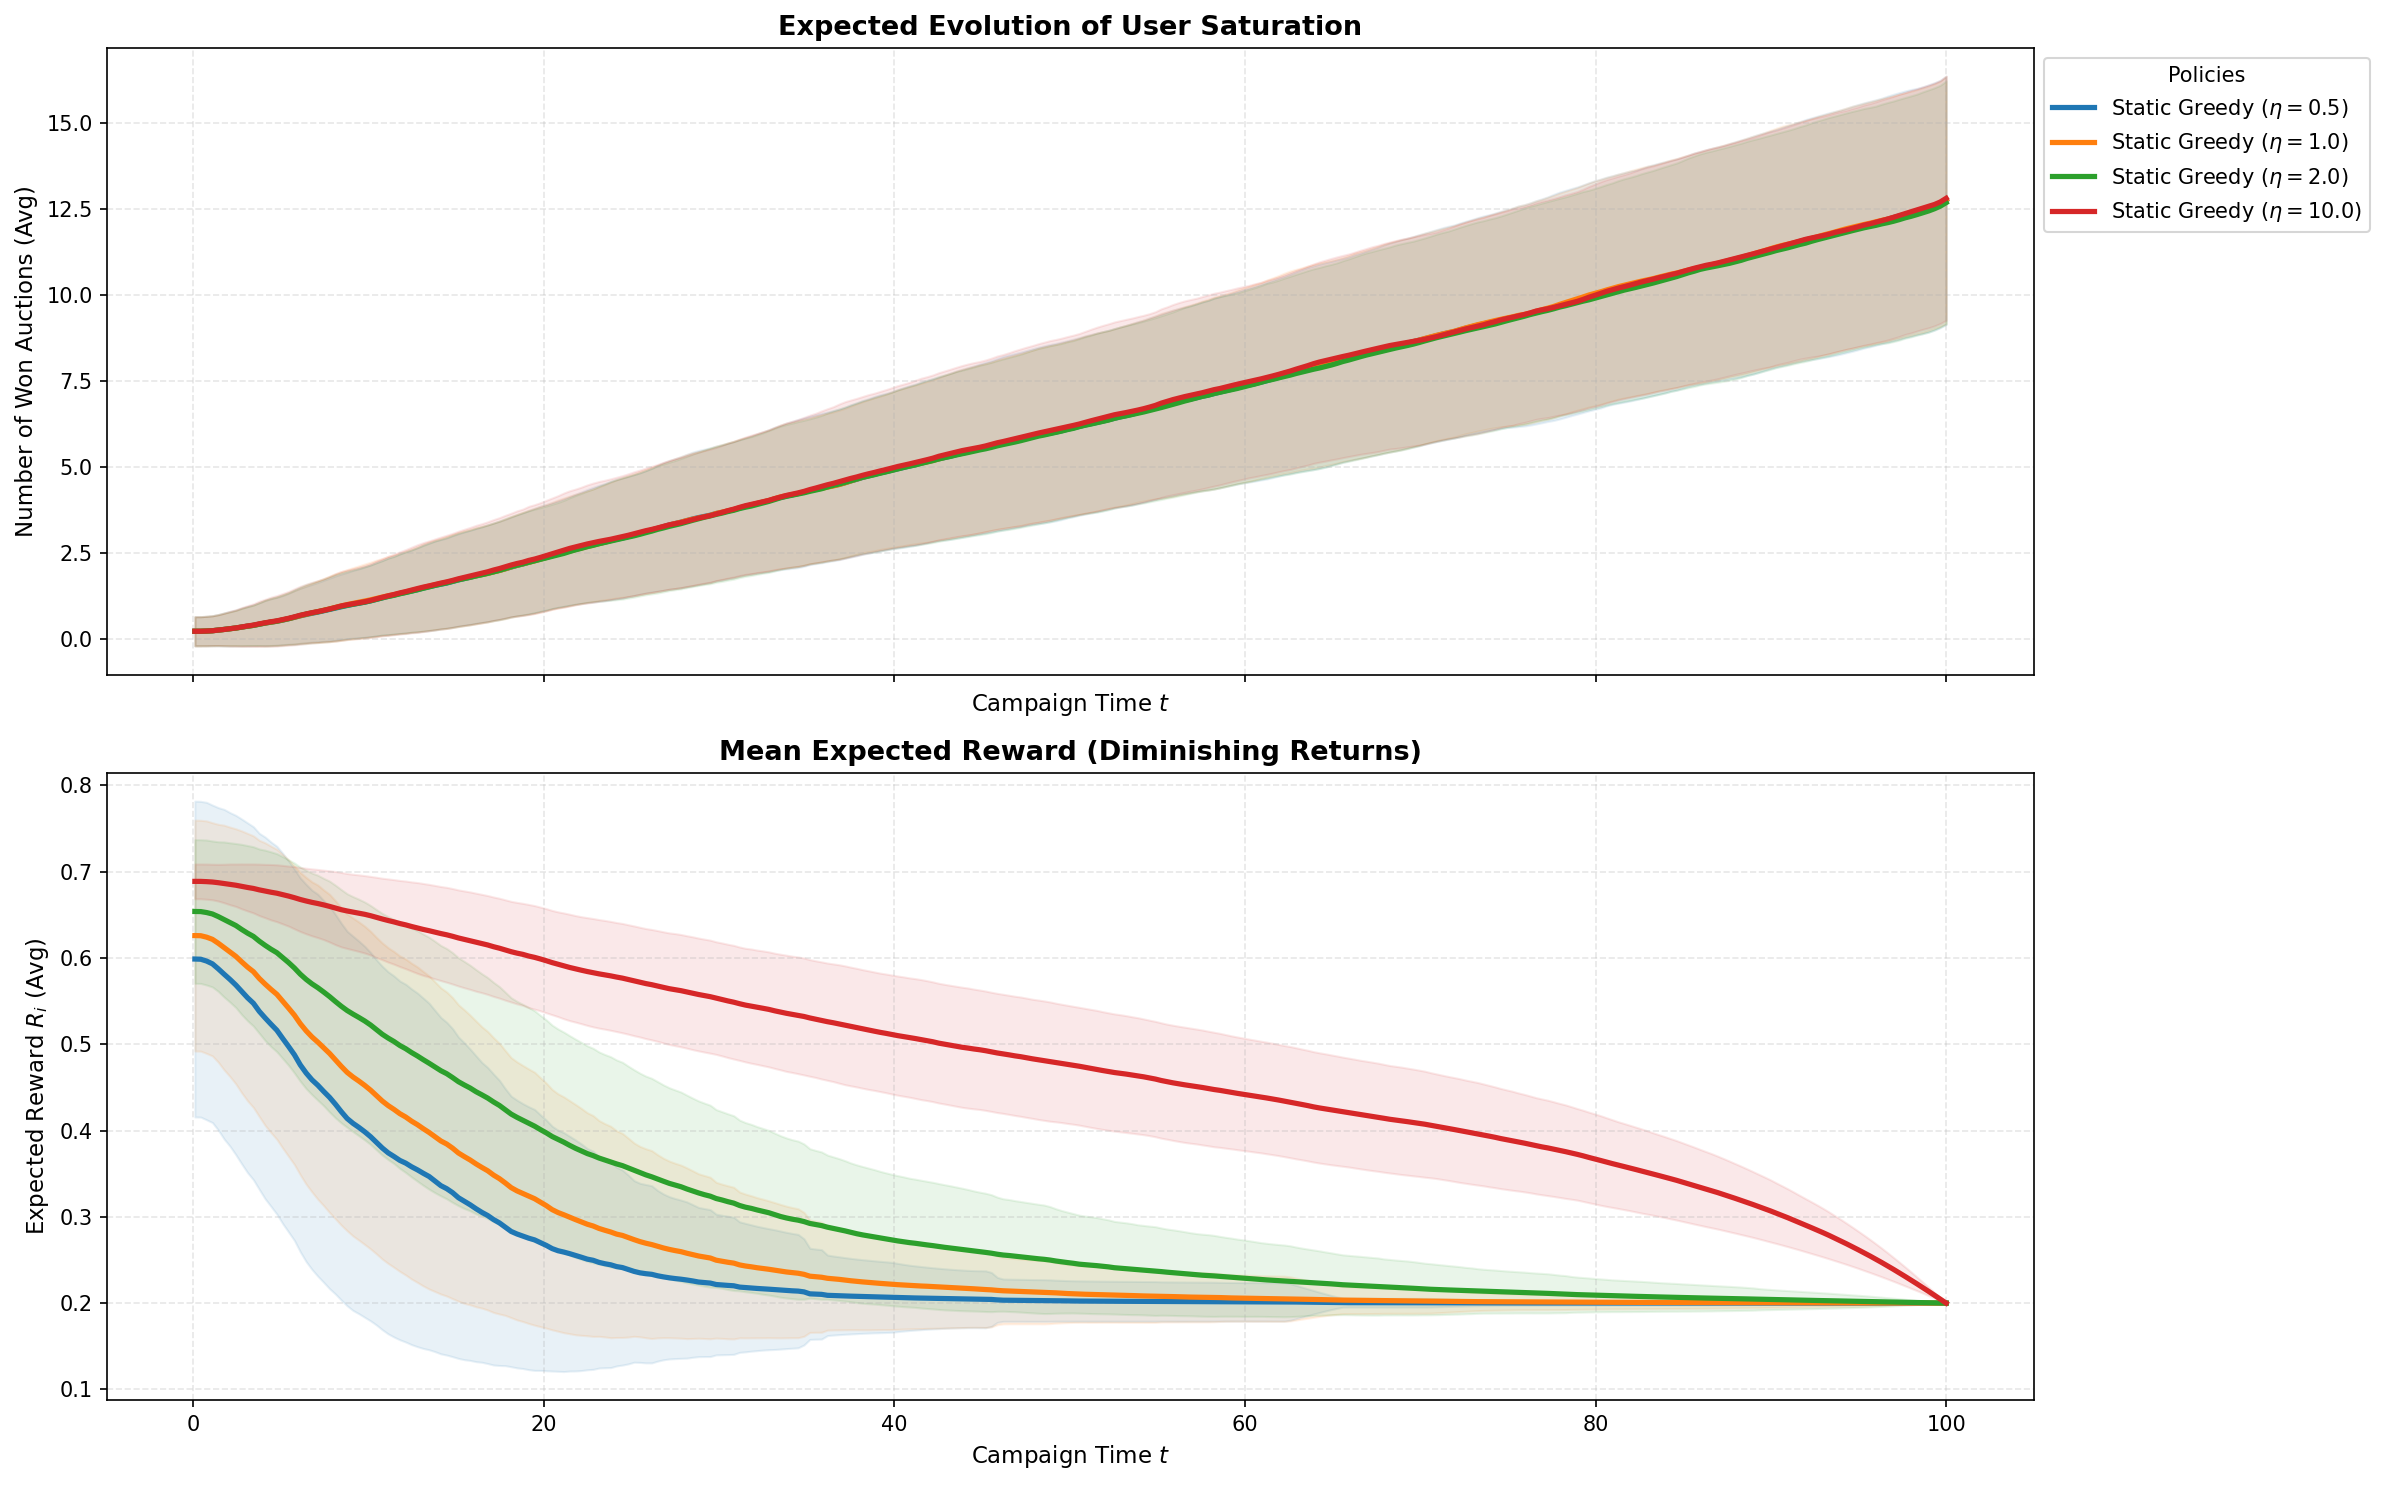

In [21]:
plot_value_dynamics_average(df_results, policies=["Static Greedy"], sat_scales=[0.5, 1.0, 2.0, 10.0], show_scatters=False)

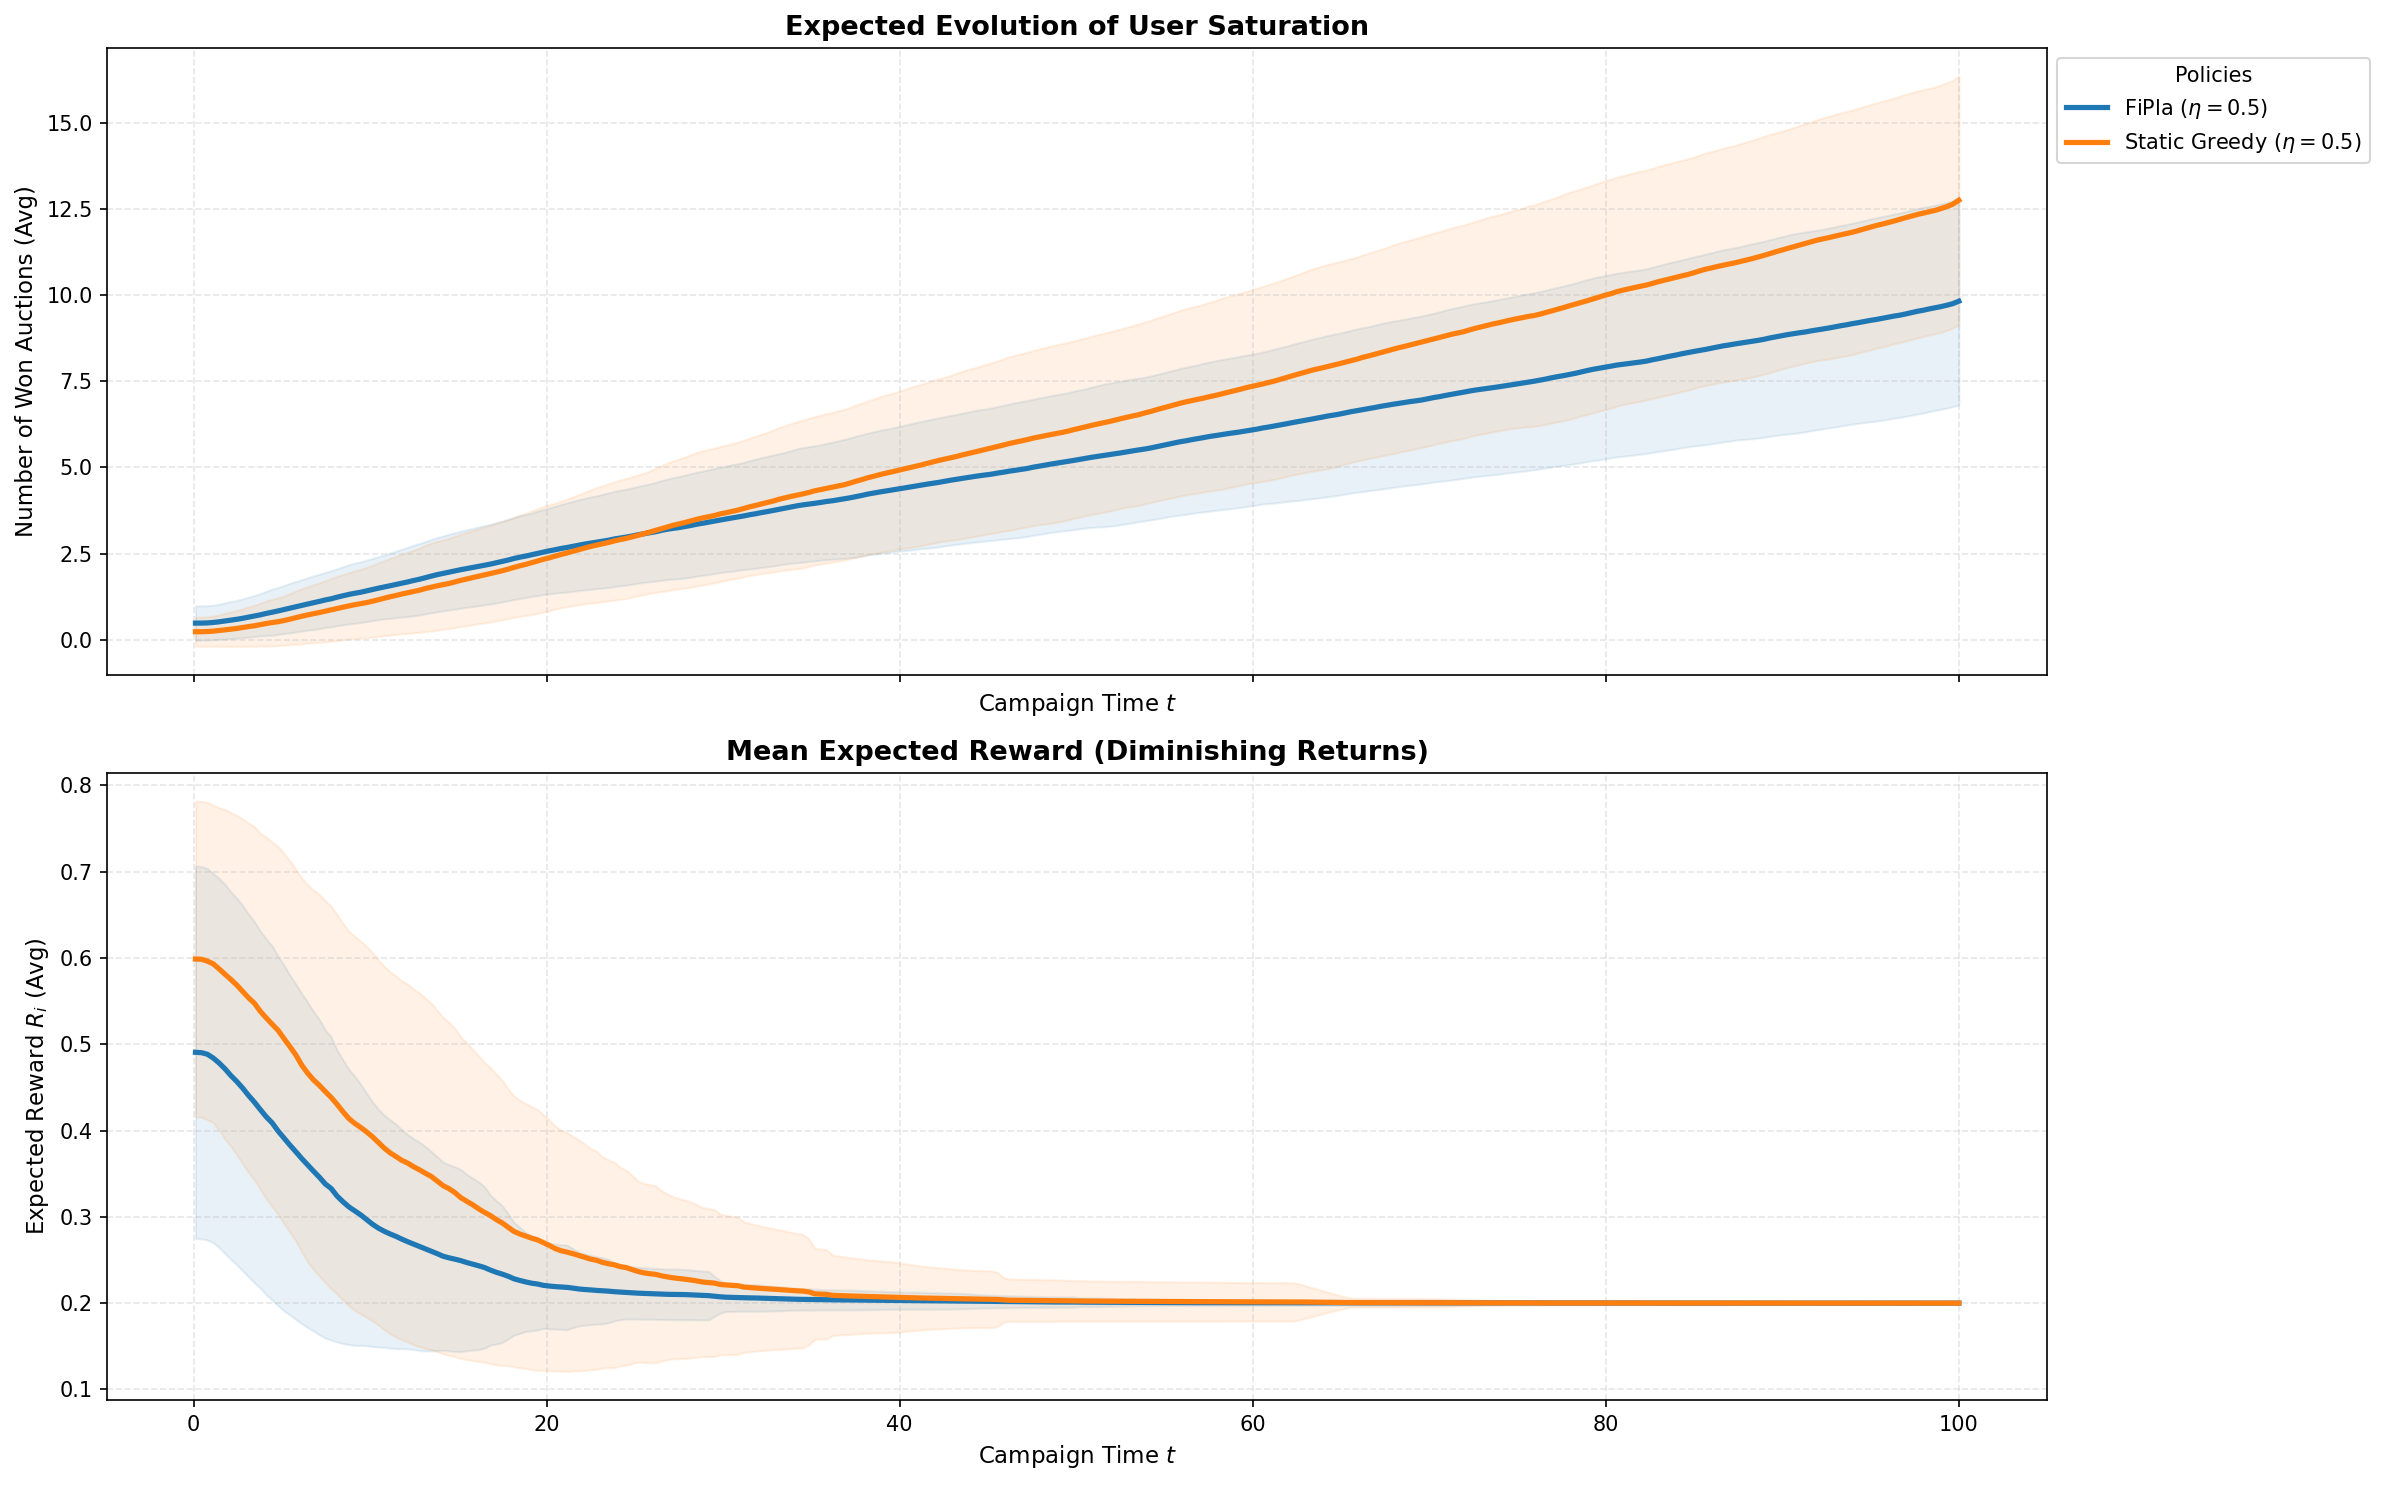

In [22]:
plot_value_dynamics_average(df_results, policies=["Static Greedy","FiPla"], sat_scales=[0.5], show_scatters=False)

=> For smaller saturation scale = 0.5, we can see that Static Greedy does continue to win more auction eventhough the expected value decreases by bidding a higher value that it is actually worth compared to FiPla but they actually have the same cumulative reward wich mean that ....

For Static greedy, we observe that the number of won auctions is almost the same across all saturation scales even though the expected reward per win is drastically different, compared to Fipla that wins less auctions over time as the saturation scale decreases. This suggests that Static greedy is not adapting to the changing user value and is likely overbidding in high saturation regimes, leading to a higher number of wins but lower overall utility due to the rapid depletion of user receptiveness. 


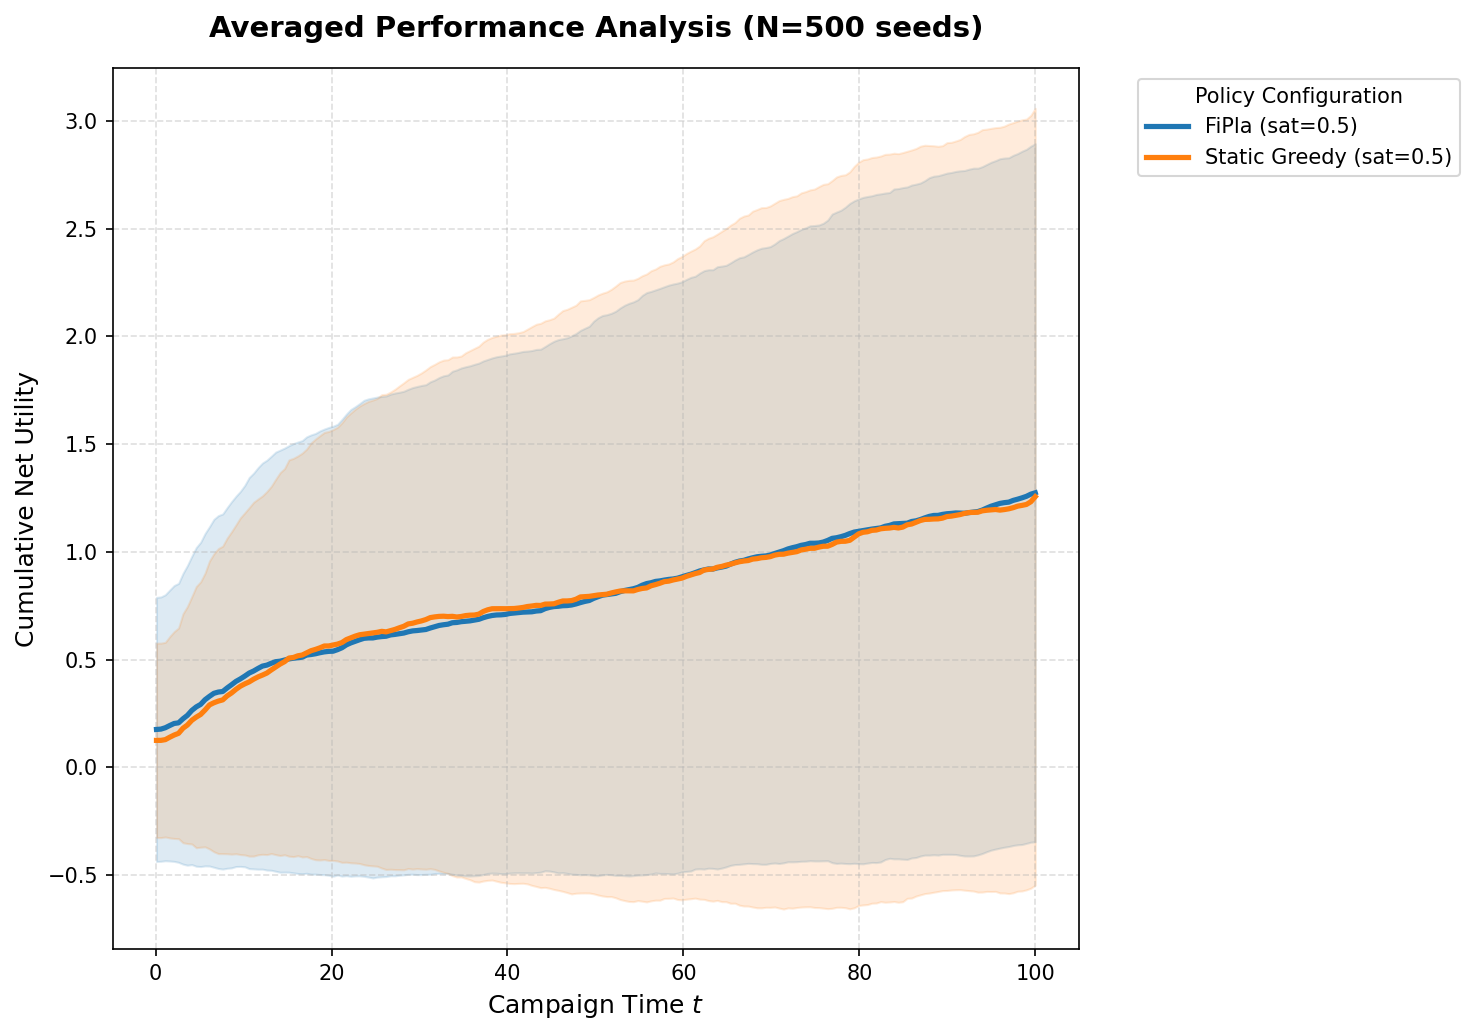

In [23]:
# Plot for ONE seed (e.g., seed=42)
plot_anarchy_results_average(df_results, sat_scales=[0.5], policies=["Static Greedy", "FiPla"])

### **3.3 Cross-Policy Dynamics: Strategic Implications**

Comparing FiPla and Static Greedy under varying saturation reveals strategic depth.


In [15]:
# Final Summary Table for Publication
print("\n" + "=" * 80)
print("TABLE 1: Final Campaign Utility Summary (for paper/appendix)")
print("=" * 80)

final_utility_pivot = final_utility.pivot_table(
    values='utility', 
    index='policy', 
    columns='sat_scale', 
    aggfunc='mean'
).round(2)

print("\nMean Final Utility by Policy and Saturation Scale:")
print(final_utility_pivot)

print("\n\nStandard Error (for error bars in figures):")
final_utility_se = final_utility.pivot_table(
    values='utility', 
    index='policy', 
    columns='sat_scale', 
    aggfunc=lambda x: x.std() / np.sqrt(len(x))
).round(3)
print(final_utility_se)

results_export = final_utility.groupby(['policy', 'sat_scale']).agg({
    'utility': ['mean', 'std', 'count']
}).round(3)

print("\n\nExport-ready summary (Markdown):")
print(results_export.to_markdown())


TABLE 1: Final Campaign Utility Summary (for paper/appendix)

Mean Final Utility by Policy and Saturation Scale:
sat_scale      0.5   1.0   2.0   10.0
policy                               
FiPla          1.41  1.56  1.76  6.37
Random        -1.44 -2.00 -0.05  3.71
Static Greedy  3.01  3.19  3.25  5.74


Standard Error (for error bars in figures):
sat_scale       0.5    1.0    2.0    10.0
policy                                   
FiPla          0.095  0.142  0.130  0.184
Random         0.061  0.127  0.164  0.175
Static Greedy  0.168  0.166  0.074  0.256


Export-ready summary (Markdown):
|                         |   ('utility', 'mean') |   ('utility', 'std') |   ('utility', 'count') |
|:------------------------|----------------------:|---------------------:|-----------------------:|
| ('FiPla', 0.5)          |                 1.413 |                0.809 |                     72 |
| ('FiPla', 1.0)          |                 1.564 |                1.207 |                     72 |
| ('F